In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    df = pd.read_csv("diamonds.csv")
except FileNotFoundError:
    sns.load_dataset("diamonds").to_csv("diamonds.csv", index=False)   # needs internet
    df = pd.read_csv("diamonds.csv")

In [3]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [4]:
print(df.shape)

(53940, 10)


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.7 MB


In [6]:
df.describe().round(1)

,carat,depth,table,price,x,y,z
count,53940.0,53940.0,53940.0,53940.0,53940.0,53940.0,53940.0
mean,0.8,61.7,57.5,3932.8,5.7,5.7,3.5
std,0.5,1.4,2.2,3989.4,1.1,1.1,0.7
min,0.2,43.0,43.0,326.0,0.0,0.0,0.0
25%,0.4,61.0,56.0,950.0,4.7,4.7,2.9
50%,0.7,61.8,57.0,2401.0,5.7,5.7,3.5
75%,1.0,62.5,59.0,5324.2,6.5,6.5,4.0
max,5.0,79.0,95.0,18823.0,10.7,58.9,31.8


In [7]:
df.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [8]:
df[["carat", "x", "y", "z"]].value_counts()

carat  x     y     z   
0.30   4.28  4.31  2.67    17
       4.29  4.32  2.68    17
0.32   4.40  4.43  2.72    16
0.30   4.31  4.33  2.67    16
       4.30  4.33  2.68    15
                           ..
0.70   5.71  5.76  3.47     1
0.72   5.75  5.76  3.50     1
       5.69  5.75  3.61     1
0.86   6.15  6.12  3.74     1
0.75   5.83  5.87  3.64     1
Name: count, Length: 43552, dtype: int64

In [9]:
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

print("Q1", q1)
print("Q3", q3)
print("IQR", iqr)
print("Lower Limit: ", low)
print("Higher Limit: ", high)

outliers = df[(df["price"] < low) | (df["price"] > high)]
print("Total outliers = ", len(outliers))

Q1 950.0
Q3 5324.25
IQR 4374.25
Lower Limit:  -5611.375
Higher Limit:  11885.625
Total outliers =  3540


In [10]:
print("Outliers based on cut")
print(outliers["cut"].value_counts())

print("\nOutliers based on color")
print(outliers["color"].value_counts())

print("\nOutliers based on clarity")
print(outliers["clarity"].value_counts())

print("\nOutliers based on carat")
print(outliers["carat"].value_counts())

Outliers based on cut
cut
Premium      1258
Ideal        1159
Very Good     757
Good          265
Fair          101
Name: count, dtype: int64

Outliers based on color
color
G    738
H    663
I    633
F    520
E    368
J    351
D    267
Name: count, dtype: int64

Outliers based on clarity
clarity
SI2     980
VS2     845
SI1     790
VS1     471
VVS2    218
VVS1    119
IF      103
I1       14
Name: count, dtype: int64

Outliers based on carat
carat
2.01    380
1.51    253
2.00    203
1.50    196
2.02    155
       ... 
2.72      1
5.01      1
4.50      1
2.67      1
3.51      1
Name: count, Length: 187, dtype: int64


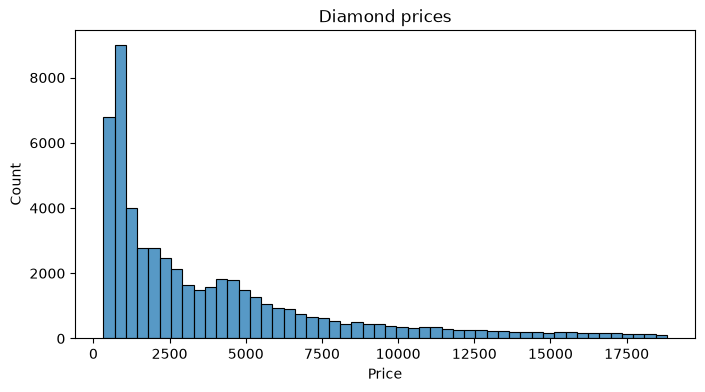

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

#HISTOGRAM
plt.figure(figsize=(8,4))
sns.histplot(df["price"], bins = 50)
plt.title("Diamond prices")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

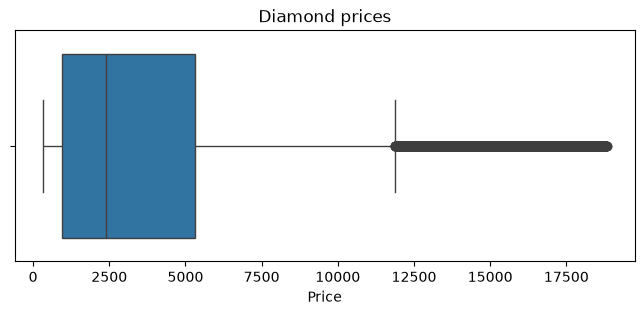

In [12]:
#BOX PLOT
plt.figure(figsize=(8,3))
sns.boxplot(x = df["price"])
plt.title("Diamond prices")
plt.xlabel("Price")
plt.show()

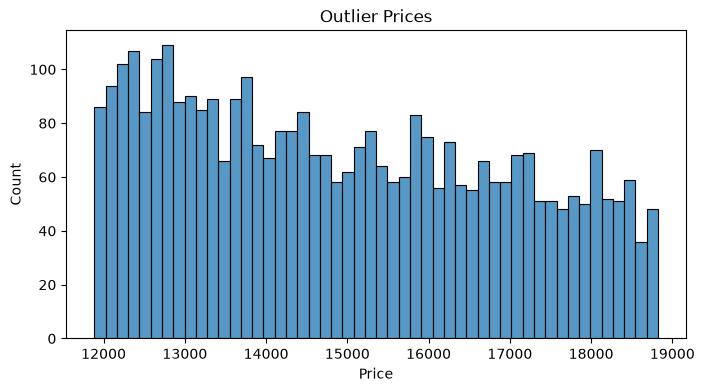

In [13]:
#HISTOGRAM FOR OUTLIERS
plt.figure(figsize=(8,4))
sns.histplot(outliers["price"], bins = 50)
plt.title("Outlier Prices")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

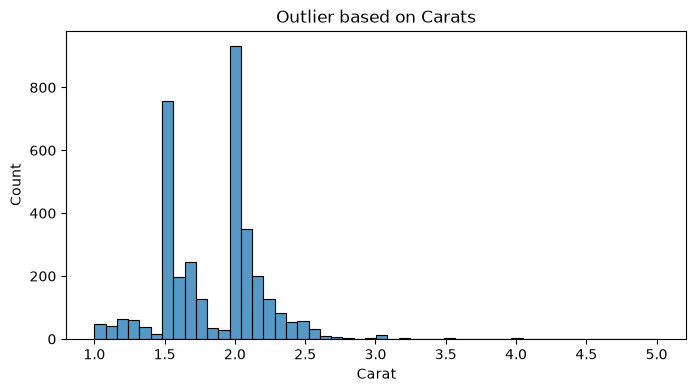

In [14]:
#HISTOGRAM OF OUTLIERS BASED ON CARATS
plt.figure(figsize=(8,4))
sns.histplot(outliers["carat"], bins = 50)
plt.title("Outlier based on Carats")
plt.xlabel("Carat")
plt.ylabel("Count")
plt.show()

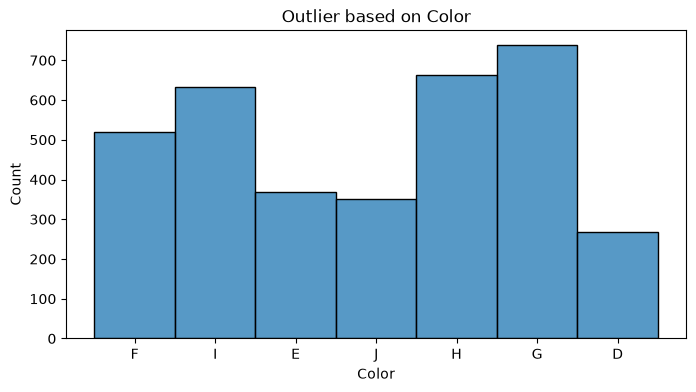

In [15]:
#HISTOGRAM OF OUTLIERS BASED ON COLOR
plt.figure(figsize=(8,4))
sns.histplot(outliers["color"], bins = 50)
plt.title("Outlier based on Color")
plt.xlabel("Color")
plt.ylabel("Count")
plt.show()

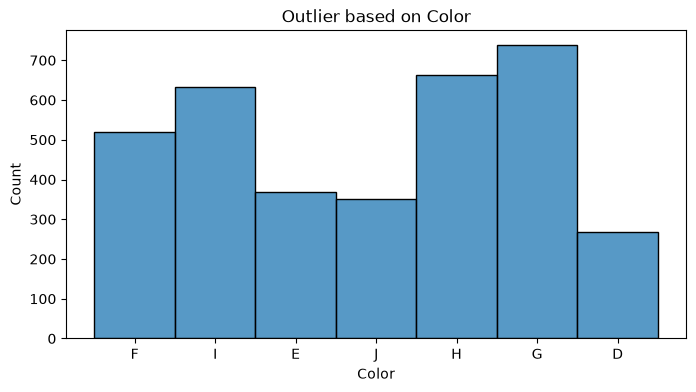

In [16]:
#HISTOGRAM OF OUTLIERS BASED ON COLOR
plt.figure(figsize=(8,4))
sns.histplot(outliers["color"], bins = 50)
plt.title("Outlier based on Color")
plt.xlabel("Color")
plt.ylabel("Count")
plt.show()

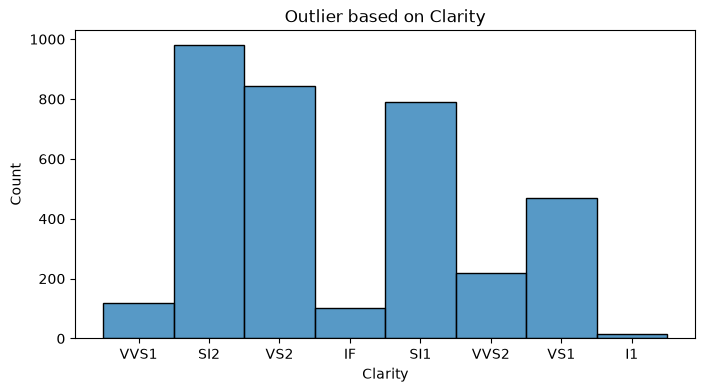

In [17]:
#HISTOGRAM OF OUTLIERS BASED ON CLARITY
plt.figure(figsize=(8,4))
sns.histplot(outliers["clarity"], bins = 50)
plt.title("Outlier based on Clarity")
plt.xlabel("Clarity")
plt.ylabel("Count")
plt.show()

5. Findings:
Finding 1 : Non-Linear Growth

Number: Diamond prices are not linear, While a 1 carat diamond costs 10000 pkr, a 2 carat diamond cost more then triple
Finding 2 : Outliers represent exceptional diamonds

Number After the using the IQR rules, 3520 were outliers. But they were not error instead those are high end rare luxury diamonds
6. Conculsion:
What drives a diamond's price? Physical size and weight('carat', with the dimensions 'x', 'y','z'), these are the primary drivers for the price change.

Are 'Ideal' cut diamonds always the most expensive? No. Cut quality does affect a little but a smaller diamond with an "ideal" cut will be cheaper then a bigger diamond with a lower grade cut.

Is pricing Linear? No, pricing is exponential, as the carats increase the price is increased by a lo9t, making larger diamonds more expensive and rare.

What are the price outliers The outliers identified by using the iqr are not actually outliers, but rare and high end luxury diamonds, they are not errors but legitamate diamonds with very high quality cuts, clarity and dimensions.